In [1]:
!nvidia-smi

Thu Oct  1 13:55:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import cv2

resim = cv2.imread("/content/image1.jpeg")

print(resim.shape)

(8640, 15360, 3)


In [3]:
from numba import cuda

print("CUDA kullanılabilir mi?", cuda.is_available())

if cuda.is_available():
    print("GPU:", cuda.get_current_device().name)


CUDA kullanılabilir mi? True
GPU: Tesla T4


In [4]:
import cv2
import numpy as np
from numba import cuda

# Resmi gri tonlamali oku
gri = cv2.imread("/content/image1.jpeg", cv2.IMREAD_GRAYSCALE)

# Boyutlari al
h, w = gri.shape

orta_y = h // 2
orta_x = w // 2

# Resmi 4 parcaya ayir
parca1 = gri[0:orta_y, 0:orta_x]
parca2 = gri[0:orta_y, orta_x:w]
parca3 = gri[orta_y:h, 0:orta_x]
parca4 = gri[orta_y:h, orta_x:w]

print("Tum resim:", gri.shape)

print("Parca 1:", parca1.shape)
print("Parca 2:", parca2.shape)
print("Parca 3:", parca3.shape)
print("Parca 4:", parca4.shape)

Tum resim: (8640, 15360)
Parca 1: (4320, 7680)
Parca 2: (4320, 7680)
Parca 3: (4320, 7680)
Parca 4: (4320, 7680)


In [5]:
from numba import cuda
import numpy as np


@cuda.jit
def histogram_cuda(image, histogram):

    # Her CUDA thread'i için bir piksel konumu
    y, x = cuda.grid(2)

    # Görüntünün sınırları içerisindeysek
    if y < image.shape[0] and x < image.shape[1]:

        # Pikselin parlaklık değerini al (0-255)
        pixel = image[y, x]

        # Histogramın ilgili kutusunu 1 artır
        cuda.atomic.add(histogram, pixel, 1)

In [7]:
import numpy as np

# Parca 1'i GPU'ya gönder
d_image = cuda.to_device(np.ascontiguousarray(parca1))

# GPU üzerinde 256 elemanli bos histogram
d_hist = cuda.to_device(
    np.zeros(256, dtype=np.int32)
)

# Her CUDA block'unda 16x16 = 256 thread
threads_per_block = (16, 16)

# Kaç block gerektiğini hesapla
blocks_per_grid_x = (
    parca1.shape[1] + threads_per_block[1] - 1
) // threads_per_block[1]

blocks_per_grid_y = (
    parca1.shape[0] + threads_per_block[0] - 1
) // threads_per_block[0]

blocks_per_grid = (
    blocks_per_grid_y,
    blocks_per_grid_x
)

# CUDA kernel'i çalıştır
histogram_cuda[blocks_per_grid, threads_per_block](
    d_image,
    d_hist
)

# GPU'nun bitirmesini bekle
cuda.synchronize()

# Histogrami GPU'dan geri al
hist1_cuda = d_hist.copy_to_host()

print(hist1_cuda)

[     0      0      0      5      2      5      6      5     18     10
     11     10     12     15     20     24     28     31     48     65
     79     80    120    124    153    182    241    236    257    245
    351    350    395    448    524    561    667    775   1036   1136
   1478   1629   1923   2090   2257   2487   2635   2743   3040   3340
   3442   3476   3716   3997   4291   4827   4640   4833   5079   5222
   5477   5902   6425   6957   7732   8138   8944   9644  10846  11514
  13222  14890  15309  16955  17799  17290  15551  14741  14298  14120
  14146  13941  13209  13037  12581  12703  12476  12281  11950  11322
  10989  11188  11531  11608  11718  11893  11764  11953  11802  11923
  12255  12439  12088  12359  12127  11588  11634  11575  11675  10963
  10722  10613  10479  10128  10033   9864   9646   9955   9705   9618
   9144   9168   8996   8715   8729   8712   8891   8581   8634   8760
   8461   8499   8999  11242  11369  13592  13379  16055  17907  20641
  2388

In [9]:
def cuda_histogram_hesapla(parca):

    # CUDA icin bellegi duzenle
    parca = np.ascontiguousarray(parca)

    # Resmi GPU'ya gonder
    d_image = cuda.to_device(parca)

    # 256 elemanli histogram olustur
    d_hist = cuda.to_device(
        np.zeros(256, dtype=np.int32)
    )

    # Her block 16x16 = 256 thread
    threads_per_block = (16, 16)

    # Gerekli block sayisini hesapla
    blocks_x = (
        parca.shape[1] + threads_per_block[1] - 1
    ) // threads_per_block[1]

    blocks_y = (
        parca.shape[0] + threads_per_block[0] - 1
    ) // threads_per_block[0]

    blocks_per_grid = (blocks_y, blocks_x)

    # CUDA kernelini calistir
    histogram_cuda[blocks_per_grid, threads_per_block](
        d_image,
        d_hist
    )

    cuda.synchronize()

    # Sonucu CPU'ya geri getir
    return d_hist.copy_to_host()

In [10]:
hist1_cuda = cuda_histogram_hesapla(parca1)
hist2_cuda = cuda_histogram_hesapla(parca2)
hist3_cuda = cuda_histogram_hesapla(parca3)
hist4_cuda = cuda_histogram_hesapla(parca4)

print("4 CUDA histogrami hesaplandi!")

4 CUDA histogrami hesaplandi!


In [11]:
ana_histogram_cuda = (
    hist1_cuda +
    hist2_cuda +
    hist3_cuda +
    hist4_cuda
)

print("Ana histogram olusturuldu!")

Ana histogram olusturuldu!


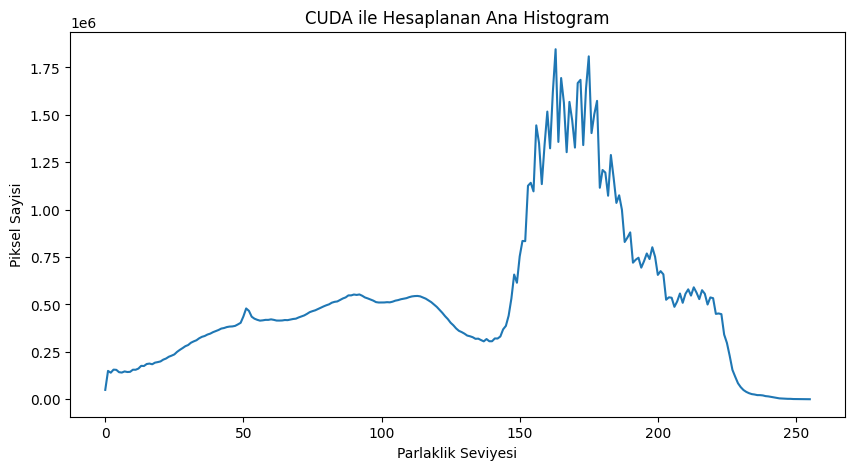

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(ana_histogram_cuda)

plt.title("CUDA ile Hesaplanan Ana Histogram")
plt.xlabel("Parlaklik Seviyesi")
plt.ylabel("Piksel Sayisi")

plt.show()

In [13]:
# CPU ile tum resmin histogramini hesapla
cpu_histogram = cv2.calcHist(
    [gri],
    [0],
    None,
    [256],
    [0, 256]
).flatten().astype(np.int32)

# CPU ve CUDA sonuclari ayni mi?
ayni_mi = np.array_equal(
    cpu_histogram,
    ana_histogram_cuda
)

print("CPU ve CUDA histogramlari ayni mi?", ayni_mi)

CPU ve CUDA histogramlari ayni mi? True


In [14]:
import time

# =========================
# CPU SURESI
# =========================

start = time.perf_counter()

cpu_hist = cv2.calcHist(
    [gri],
    [0],
    None,
    [256],
    [0, 256]
)

end = time.perf_counter()

cpu_sure = (end - start) * 1000


# =========================
# CUDA SURESI
# =========================

# CUDA'yi bir kez isinma amacli calistir
_ = cuda_histogram_hesapla(parca1)

start = time.perf_counter()

hist1 = cuda_histogram_hesapla(parca1)
hist2 = cuda_histogram_hesapla(parca2)
hist3 = cuda_histogram_hesapla(parca3)
hist4 = cuda_histogram_hesapla(parca4)

ana_hist = hist1 + hist2 + hist3 + hist4

end = time.perf_counter()

cuda_sure = (end - start) * 1000


print("CPU suresi :", cpu_sure, "ms")
print("CUDA suresi:", cuda_sure, "ms")

CPU suresi : 99.04458800019711 ms
CUDA suresi: 146.15354299985484 ms
